In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tqdm
import functools

from spatial_lda.featurization import featurize_samples
from spatial_lda.featurization import neighborhood_to_cluster
from spatial_lda.featurization import neighborhood_to_avg_marker
from spatial_lda.featurization import make_nearest_neighbor_graph
from spatial_lda.featurization import make_merged_difference_matrices
from spatial_lda.featurization import featurize_spleens
from spatial_lda.visualization import plot_samples_in_a_row
from spatial_lda.visualization import plot_bcell_topic_multicolor
import spatial_lda.model

plt.style.use('dark_background')


In [17]:
df = pd.read_csv('../data/simulated/Case3_GeneExpression_Pos.csv', index_col=0)
df.head()

,x,y,anchor,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,...,gene_191,gene_192,gene_193,gene_194,gene_195,gene_196,gene_197,gene_198,gene_199,gene_200
0,39.0,249.0,True,97.978344,288.744310,207.439950,130.729301,145.973755,93.625536,94.501388,...,123.990653,127.405828,199.418694,231.779543,49.843936,240.440285,238.924167,251.999468,288.545936,267.265960
1,221.0,355.0,True,109.176702,302.593459,209.472481,136.090831,139.685584,93.812608,100.759236,...,121.309934,141.642276,211.141503,239.099988,49.644412,226.937675,217.716232,254.521207,286.011504,259.388158
2,94.0,224.0,True,105.069111,286.478912,206.270129,122.295103,151.061611,93.811637,97.503040,...,124.236551,139.787360,192.724303,230.260430,53.227274,227.379082,213.038513,256.593428,284.531722,257.453728
3,163.0,79.0,True,94.169471,299.462004,207.342509,143.434911,151.919988,95.137000,88.634311,...,123.678286,154.067963,196.902069,235.637872,48.645942,232.737396,203.091107,259.928301,285.873585,261.001497
4,84.0,366.0,True,105.411591,296.165931,211.474442,126.705122,151.016157,93.158132,94.272897,...,117.947428,148.542998,210.460572,241.112089,50.749449,231.546437,218.963055,250.917589,287.094299,260.321744


In [18]:
N_TOPICS = 2
DIFFERENCE_PENALTY = 250 #just pulled from the example in the paper
ANCHORNAME = 'all'
PATH_TO_MODELS = '../results/'
EXPERIMENT = 'Case3Calico'

PATH_TO_TRAIN_MODEL = '_'.join((f'{PATH_TO_MODELS}/{EXPERIMENT}',
                                f'penalty={DIFFERENCE_PENALTY}',
                                f'topics={N_TOPICS}',
                                f'anchor={ANCHORNAME}')) + '.pkl'
PATH_TO_COMPLETE_MODEL = '_'.join((f'{PATH_TO_MODELS}/{EXPERIMENT}',
                                f'penalty={DIFFERENCE_PENALTY}',
                                f'topics={N_TOPICS}',
                                f'anchor={ANCHORNAME}')) + '.pkl'

In [19]:
markers = df.columns[3:]

sample_ids = [1]
sample_dfs = [df]
sample_dict = dict(zip(sample_ids, sample_dfs))

neighborhood_feature_fn = functools.partial(neighborhood_to_avg_marker, 
                                              markers=markers)

features = featurize_samples(sample_dfs = sample_dict,
                  neighborhood_feature_fn = neighborhood_feature_fn,
                  radius = 100,
                  is_anchor_col  = 'anchor',
                  x_col = 'x',
                  y_col = 'y',
                  include_anchors=True)

In [20]:
difference_matrices = make_merged_difference_matrices(sample_features = features,
                                sample_dfs = sample_dict,
                                x_col = 'x',
                                y_col = 'y')



In [21]:
spatial_lda_model = spatial_lda.model.train(features, 
                                            difference_matrices, 
                                            n_topics=N_TOPICS, 
                                            difference_penalty=DIFFERENCE_PENALTY, 
                                            verbosity=1,
                                            n_parallel_processes=3,
                                            n_iters=3,
                                            admm_rho=0.1,
                                            primal_dual_mu=2)



In [22]:
complete_lda = spatial_lda.model.infer(spatial_lda_model.components_, 
                                       features, 
                                       difference_matrices, 
                                       difference_penalty=DIFFERENCE_PENALTY,
                                       n_parallel_processes=3)

In [23]:
import palettable.cartocolors.qualitative as qual_palettes

def plot_colored_cells(complete_lda, feature_df, FIG_FILE=None):
    fig, ax = plt.subplots(1,1, figsize=(5,5))
    topic_weights = complete_lda.topic_weights
    color_palette = qual_palettes.Bold_10.mpl_colors
    colors = np.array(color_palette[:topic_weights.shape[1]])
    cell_coords = feature_df
    non_anchor_coords = cell_coords[~cell_coords.anchor]
    ax.scatter(
            non_anchor_coords['x'],
            non_anchor_coords['y'],
            s=6,
            c='k',
            marker='x',
            label='Non-Anchor',
            alpha=.2)
    cell_indices = topic_weights.index.map(lambda x: x[1])
    coords = cell_coords.loc[cell_indices]

    ax.scatter(coords['x'], coords['y'], s=3,
                   c=colors[np.argmax(np.array(topic_weights), axis=1), :])

    ax.axes.get_yaxis().set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    
    if FIG_FILE != None:
        plt.savefig(FIG_FILE)

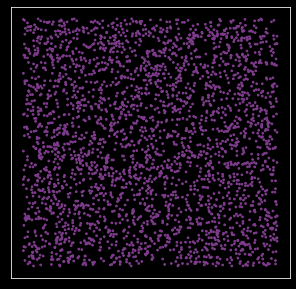

In [24]:
plot_colored_cells(complete_lda, sample_dict[1])


In [21]:
import pickle
with open(PATH_TO_TRAIN_MODEL, 'wb') as f:
    pickle.dump(spatial_lda_model, f)

with open(PATH_TO_COMPLETE_MODEL, 'wb') as f:
    pickle.dump(complete_lda, f)

In [14]:
topic_weights = complete_lda.topic_weights

In [25]:
topic_weights



,Topic-0,Topic-1
"(1, 0)",0.517872,0.482128
"(1, 1)",0.518926,0.481074
"(1, 2)",0.518610,0.481390
"(1, 3)",0.520520,0.479480
"(1, 4)",0.518891,0.481109
...,...,...
"(1, 2995)",0.525136,0.474864
"(1, 2996)",0.519759,0.480241
"(1, 2997)",0.521584,0.478416
"(1, 2998)",0.518780,0.481220
